# Konversi Citra ke Grayscale 8-bit
`data/rapi`, `data/berantakan` → `grayscale/rapi`, `grayscale/berantakan` (PNG, nilai 0–255)

In [1]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt

FOLDER_DATA = "data"
FOLDER_GRAY = "grayscale"
KELAS = ["rapi", "berantakan"]
EKSTENSI = (".jpg", ".jpeg", ".png", ".bmp", ".webp")

def baca(path, flag=cv2.IMREAD_COLOR):
    img = cv2.imread(path, flag)
    if img is None:  # fallback path Windows
        img = cv2.imdecode(np.fromfile(path, dtype=np.uint8), flag)
    return img

In [2]:
for kelas in KELAS:
    src = os.path.join(FOLDER_DATA, kelas)
    dst = os.path.join(FOLDER_GRAY, kelas)
    os.makedirs(dst, exist_ok=True)
    n = 0
    for nama in os.listdir(src):
        if nama.lower().endswith(EKSTENSI):
            gray = cv2.cvtColor(baca(os.path.join(src, nama)), cv2.COLOR_BGR2GRAY)   # 0.299R + 0.587G + 0.114B
            out = os.path.join(dst, os.path.splitext(nama)[0] + ".png")             # PNG: tanpa kompresi lossy
            cv2.imencode(".png", gray)[1].tofile(out)
            n += 1
    print(f"{kelas}: {n} citra -> {dst}")

rapi: 76 citra -> grayscale\rapi
berantakan: 97 citra -> grayscale\berantakan


RGB : (1792, 2400, 3) uint8
Gray: (1792, 2400) uint8 | min-max: 0 - 255


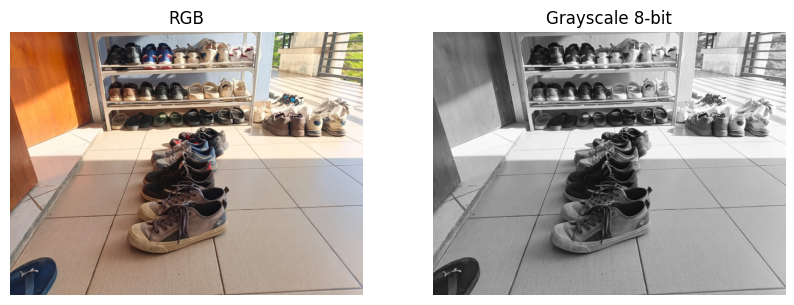

In [3]:
nama = sorted(os.listdir(os.path.join(FOLDER_DATA, "rapi")))[0]
rgb = cv2.cvtColor(baca(os.path.join(FOLDER_DATA, "rapi", nama)), cv2.COLOR_BGR2RGB)
gray = baca(os.path.join(FOLDER_GRAY, "rapi", os.path.splitext(nama)[0] + ".png"), cv2.IMREAD_GRAYSCALE)
print("RGB :", rgb.shape, rgb.dtype)
print("Gray:", gray.shape, gray.dtype, "| min-max:", gray.min(), "-", gray.max())

fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ax[0].imshow(rgb); ax[0].set_title("RGB")
ax[1].imshow(gray, cmap="gray", vmin=0, vmax=255); ax[1].set_title("Grayscale 8-bit")
for a in ax: a.axis("off")
plt.show()